# Louvain 3.0

## Imports 

In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.neighbors import NearestNeighbors
import networkx as nx
from plotnine import *
from community.community_louvain import best_partition 

## LOAD DATA

In [ ]:
data_name = "CPN27_mod"
CSV_PATH = f"../../data/{data_name}.csv"     # <-- change to your CSV name if needed
OUTPUT_PREFIX = "../../data/results/es/images_sensitivity/"  # files will be prefixed with this

# Robust read: try comma, else semicolon
try:
    df = pd.read_csv(CSV_PATH, encoding='latin-1') # Added encoding='latin-1'
    if not {"concept","participant","property"}.issubset(df.columns):
        raise ValueError("Columns not found with comma delimiter")
except Exception:
    df = pd.read_csv(CSV_PATH, sep=";", engine="python", encoding='latin-1') # Added encoding='latin-1'

required_cols = {"concept","participant","property"}
assert required_cols.issubset(df.columns), f"CSV must have columns {required_cols}"

## Text Cleaning

LIGHT NORMALIZATION (helps avoid a single mushy cluster)

In [ ]:
STOP = set("""
el la los las un una unos unas de del al y o u que a en con por para muy se lo la le les su sus
es son esta este esto estas estos puede pueden puedes puedo podría podrian podria tener tiene tienen tienes
ser soy eres somos era eran estar esta están
""".split())

def normalize_text(s: str):
    s = s.lower().strip()
    s = re.sub(r"[^a-záéíóúüñ0-9\s]", " ", s)
    toks = [t for t in s.split() if t and (t not in STOP) and len(t)>1]
    return " ".join(toks)

df["property_norm"] = df["property"].astype(str).map(normalize_text)


## Sentence Embedding

EMBEDDINGS (Multilingual E5 + proper 'passage:' prefix) 

In [6]:
model = SentenceTransformer("intfloat/multilingual-e5-base")

def encode_passages(texts):
    return model.encode([f"passage: {t}" for t in texts],
                        normalize_embeddings=True,
                        convert_to_numpy=True)

X = encode_passages(df["property_norm"].tolist())

## Functions 

In [7]:

# ---------- 3) kNN GRAPH BUILDER ----------
def knn_graph(X, k=15, sim_min=0.36):
    nbrs = NearestNeighbors(n_neighbors=k+1, metric="cosine").fit(X)
    dist, idx = nbrs.kneighbors(X)
    
    G = nx.Graph(); G.add_nodes_from(range(len(X)))
    add_edge = G.add_edge
    for i in range(len(X)):
        for j, d in zip(idx[i], dist[i]):
            sim = 1.0 - float(d)
            if sim >= sim_min and i != j:
                add_edge(i, int(j), weight=sim)
    return G


# ---------- 4) LOUVAIN ----------
def louvain_labels(G, resolution=1.0, seed=42):
    part = best_partition(G, resolution=resolution, random_state=seed)
    labels = np.full(G.number_of_nodes(), -1, dtype=int)
    for n, c in part.items():
        labels[n] = c
    return labels

# ---------- 5) POST: SINGLETONS AS UNIQUE CODES ----------
def assign_singletons_as_unique(df_in, labels):
    out = df_in.copy()
    out["code"] = labels
    if (out["code"] == -1).any():
        mask = out["code"] == -1
        max_lbl = out["code"].max() if (out["code"]!=-1).any() else -1
        out.loc[mask, "code"] = np.arange(mask.sum(), dtype=int) + max_lbl + 1
    return out

# ---------- 6) COVERAGE & LOSS ----------
def cover_loss(df_codes, C_target=0.60):
    """
    Calcula la pérdida de cobertura por concepto usando:
        Ĉ = 1 - (Q1 / U) * ( Q1*(T-1) / ( Q1*(T-1) + 2*Q2 ) )
    donde:
        U = total de propiedades brutas para el concepto (número de filas)
        T = número de participantes distintos para el concepto
        Q1 = número de códigos mencionados por 1 participante
        Q2 = número de códigos mencionados por 2 participantes
    """
    losses = []
    covs = []
    rows = []

    for concept, grp in df_codes.groupby("concept"):
        # U: total de propiedades brutas (todas las filas de ese concepto)
        U = len(grp)

        # T: número de participantes distintos
        T = grp["participant"].nunique()

        # freq: cuántos participantes mencionaron cada código
        freq = grp.groupby("code")["participant"].nunique().values
        Q1 = int((freq == 1).sum())
        Q2 = int((freq == 2).sum())

        if T <= 1:
            C_hat = 0.0
        else:
            denom = Q1 * (T - 1) + 2 * Q2
            if denom > 0:
                C_hat = 1 - (Q1 / U) * (Q1 * (T - 1) / denom)
            else:
                # si no hay info para corregir, cobertura baja
                C_hat = 1 - (Q1 / U)

        covs.append(C_hat)
        losses.append((C_hat - C_target) ** 2)
        rows.append({
            "concept": concept,
            "U": U,
            "T": T,
            "Q1": Q1,
            "Q2": Q2,
            "coverage": C_hat
        })

    metrics_df = pd.DataFrame(rows)
    return float(np.mean(losses)), float(np.mean(covs)), metrics_df


## Hyperparameter Search

In [29]:
k=1
resolution = 0.6
sim_min = 0.33

G = knn_graph(X, k=k, sim_min=sim_min)
labels = louvain_labels(G, resolution=resolution)

df_try = assign_singletons_as_unique(df, labels)
L, Cbar, per_concept = cover_loss(df_try, C_target=0.6)

print(Cbar) 

0.8970888998710818


In [16]:
grid_k = np.arange(1, 41, 1)
resolution = 0.6
sim_min = 0.33


Cbar_values_k = np.zeros([grid_k.shape[0]])


for i, k in enumerate(grid_k):
    G = knn_graph(X, k=k, sim_min=sim_min)
    labels = louvain_labels(G, resolution=resolution)

    df_try = assign_singletons_as_unique(df, labels)
    L, Cbar, per_concept = cover_loss(df_try, C_target=0.6)

    Cbar_values_k[i] = Cbar



In [ ]:

plot_k = (
    ggplot() + theme_bw()
    + geom_line(aes(x = grid_k, y = Cbar_values_k), color = 'red')
    + geom_hline(yintercept = 0.6)
    + labs(title="Coverage variation respect to k", x="k", y="Coverage")
    
    )

plot_k.save(OUTPUT_PREFIX + f"{data_name}_coverage_k.png")

c:\Users\dra98\AppData\Local\Programs\Python\Python310\lib\site-packages\plotnine\ggplot.py:718: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\dra98\AppData\Local\Programs\Python\Python310\lib\site-packages\plotnine\ggplot.py:719: PlotnineWarning: Filename: ../../data/results/images/CPN27_mod_coverage_k.png


In [18]:
k_val = 1
grid_resolution = np.arange(0.05, 2.51, 0.05)
sim_min = 0.33


Cbar_values_res = np.zeros([grid_resolution.shape[0]])


for i, r in enumerate(grid_resolution):
    G = knn_graph(X, k=k_val, sim_min=sim_min)
    labels = louvain_labels(G, resolution=r)

    df_try = assign_singletons_as_unique(df, labels)
    L, Cbar, per_concept = cover_loss(df_try, C_target=0.6)

    Cbar_values_res[i,] = Cbar


In [ ]:


plot_resolution = (
    ggplot() + theme_bw()
    + geom_line(aes(x = grid_resolution, y = Cbar_values_res), color = 'red')
    + geom_hline(yintercept = 0.6)
    + labs(title="Coverage variation respect to resolution", x="resolution", y="Coverage")

    )

plot_resolution.save(OUTPUT_PREFIX + f"{data_name}_coverage_resolution.png")

c:\Users\dra98\AppData\Local\Programs\Python\Python310\lib\site-packages\plotnine\ggplot.py:718: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\dra98\AppData\Local\Programs\Python\Python310\lib\site-packages\plotnine\ggplot.py:719: PlotnineWarning: Filename: ../../data/results/images/CPN27_mod_coverage_resolution.png


In [ ]:
k_val = 1
resolution = 0.6
grid_sim_min = np.arange(0.5, 1, 0.01)


Cbar_values_sim = np.zeros([grid_sim_min.shape[0]])


for i, sim_min in enumerate(grid_sim_min):
    G = knn_graph(X, k=k_val, sim_min=sim_min)
    labels = louvain_labels(G, resolution=resolution)

    df_try = assign_singletons_as_unique(df, labels)
    L, Cbar, per_concept = cover_loss(df_try, C_target=0.6)

    Cbar_values_sim[i,] = Cbar

In [ ]:


plot_sim_min = (
    ggplot() + theme_bw()
    + geom_line(aes(x = grid_sim_min, y = Cbar_values_sim), color = 'red')
    + geom_hline(yintercept = 0.6)
    + labs(title="Coverage variation respect to sim_min", x="sim_min", y="Coverage")
    )

plot_sim_min.save(OUTPUT_PREFIX + f"{data_name}_coverage_sim_min.png")

c:\Users\dra98\AppData\Local\Programs\Python\Python310\lib\site-packages\plotnine\ggplot.py:718: PlotnineWarning: Saving 6.4 x 4.8 in image.
c:\Users\dra98\AppData\Local\Programs\Python\Python310\lib\site-packages\plotnine\ggplot.py:719: PlotnineWarning: Filename: ../../data/results/images/CPN27_mod_coverage_sim_min.png


# Grid Exploration

## K vs RESOLUTION

In [64]:
grid_k          = np.arange(1, 41, 1)
grid_resolution = np.arange(0.05, 2.51, 0.05)
sim_min = 0.1



max_c = 0
pos_c = [0,0]
Cbar_values = np.zeros([grid_k.shape[0], grid_resolution.shape[0]])
q1_values = np.zeros([grid_k.shape[0], grid_resolution.shape[0]])
q2_values = np.zeros([grid_k.shape[0], grid_resolution.shape[0]])

for i, k in enumerate(grid_k):
    G = knn_graph(X, k=k, sim_min=sim_min)
    for j, r in enumerate(grid_resolution):
        labels = louvain_labels(G, resolution=r)

        df_try = assign_singletons_as_unique(df, labels)
        L, Cbar, per_concept = cover_loss(df_try, C_target=0.6)

        Cbar_values[i, j] = Cbar
        if (Cbar > max_c):
            max_c = Cbar
            pos_c = [i,j]
        q1_values[i,j] = per_concept['Q1'].mean()
        q2_values[i,j] = per_concept['Q2'].mean()


In [65]:
print("k =", grid_k[pos_c[0]])
print("resolution =",grid_resolution[pos_c[1]])
print("Coverage =",max_c)

k = 40
resolution = 0.8
Coverage = 0.998983146503676


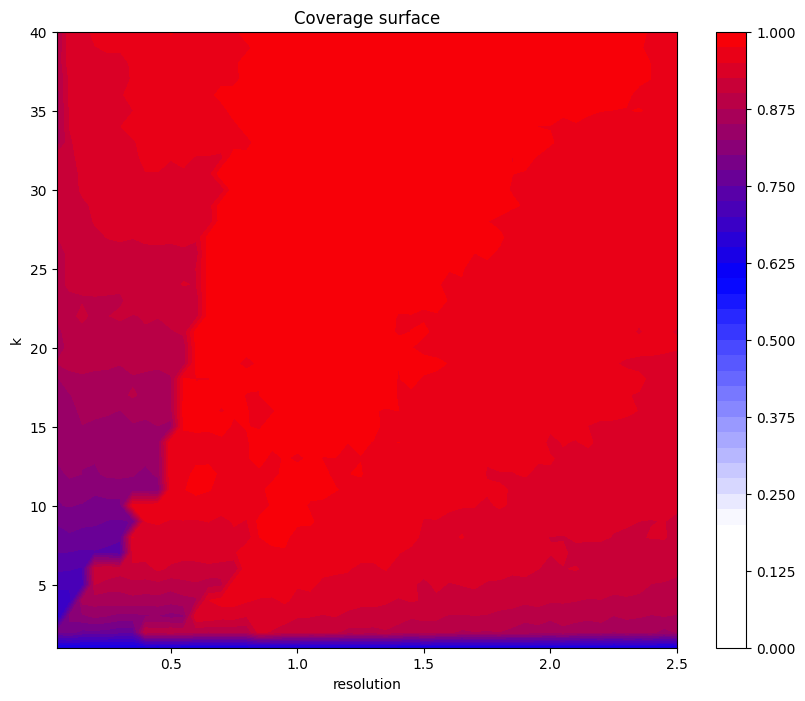

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

plt.figure(figsize = (10,8))
colors = [(0, 'white'), (0.2, 'white'), (0.6, 'blue'), (1, 'red')]
custom_cmap = LinearSegmentedColormap.from_list('custom', colors)
CS = plt.contourf( grid_resolution, grid_k, Cbar_values, levels = np.linspace(0.0, 1.0, 41), cmap =custom_cmap)
plt.colorbar(CS)
# plt.clabel(CS, CS.levels, fmt='%.2f', inline=True, fontsize=10)
# plt.plot(grid_resolution[pos_c[1]],grid_k[pos_c[0]], 'bo') 
plt.ylabel('k')
plt.xlabel('resolution')
plt.title("Coverage surface")
plt.savefig(OUTPUT_PREFIX + f"{data_name}_2d_curvas_nivel_coverage.png", bbox_inches = None)
plt.show()

## RESOLUTION vs SIM MIN

In [44]:
k = 1
grid_resolution = np.arange(0.05, 2.51, 0.05)
grid_sim_min = np.arange(0.7, 1.0, 0.01)



max_c = 0
pos_c = [0,0]
Cbar_values = np.zeros([grid_sim_min.shape[0], grid_resolution.shape[0]])


for i, sim_min in enumerate(grid_sim_min):
    G = knn_graph(X, k=k, sim_min=sim_min)
    for j, r in enumerate(grid_resolution):
        labels = louvain_labels(G, resolution=r)

        df_try = assign_singletons_as_unique(df, labels)
        L, Cbar, per_concept = cover_loss(df_try, C_target=0.6)

        Cbar_values[i, j] = Cbar
        if (Cbar > max_c):
            max_c = Cbar
            pos_c = [i,j]


In [52]:
print("sim_min =", grid_sim_min[pos_c[0]])
print("resolution =",grid_resolution[pos_c[1]])
print("Coverage =",max_c)

sim_min = 0.7
resolution = 0.35000000000000003
Coverage = 0.6209433221344284


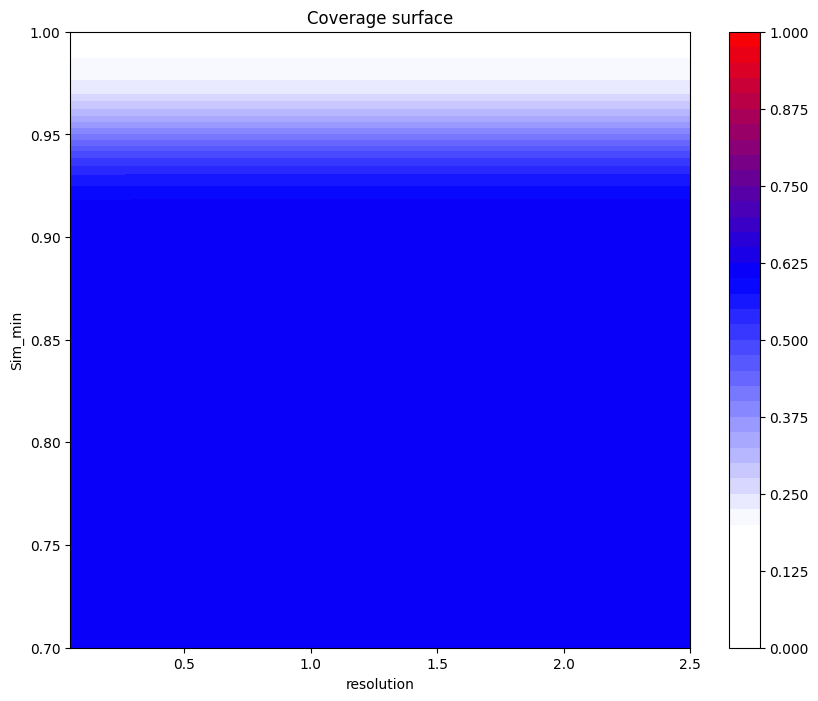

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

plt.figure(figsize = (10,8))
colors = [(0, 'white'), (0.2, 'white'), (0.6, 'blue'), (1, 'red')]
custom_cmap = LinearSegmentedColormap.from_list('custom', colors)
CS = plt.contourf(grid_resolution, grid_sim_min, Cbar_values, levels = np.linspace(0.0, 1.0, 41), cmap =custom_cmap)
plt.colorbar(CS)
# plt.clabel(CS, CS.levels, fmt='%.2f', inline=True, fontsize=10)
# plt.plot(grid_resolution[pos_c[1]],grid_k[pos_c[0]], 'bo') 
plt.ylabel('Sim_min')
plt.xlabel('resolution')
plt.title("Coverage surface")
plt.savefig(OUTPUT_PREFIX + f"{data_name}_2d_curvas_nivel_coverage_res_simmin.png", bbox_inches = None)
plt.show()

## K vs SIM_MIN

In [53]:
grid_k = np.arange(1, 41, 1)
r = 0.6
grid_sim_min = np.arange(0.7, 1.0, 0.01)


max_c = 0
pos_c = [0,0]
Cbar_values = np.zeros([grid_k.shape[0], grid_sim_min.shape[0]])


for i, k in enumerate(grid_k):
    for j, sim_min in enumerate(grid_sim_min):

        G = knn_graph(X, k=k, sim_min=sim_min)
        labels = louvain_labels(G, resolution=r)

        df_try = assign_singletons_as_unique(df, labels)
        L, Cbar, per_concept = cover_loss(df_try, C_target=0.6)

        Cbar_values[i, j] = Cbar
        if (Cbar > max_c):
            max_c = Cbar
            pos_c = [i,j]


In [54]:
print("k =", grid_k[pos_c[0]])
print("resolution =",grid_sim_min[pos_c[1]])
print("Coverage =",max_c)

k = 24
resolution = 0.8600000000000001
Coverage = 0.9891468158156079


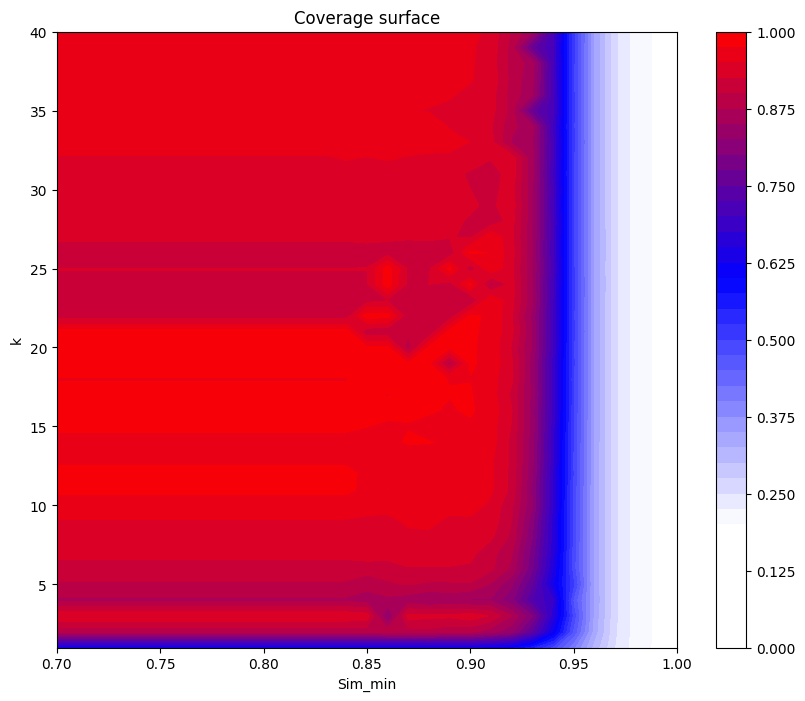

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

plt.figure(figsize = (10,8))
colors = [(0, 'white'), (0.2, 'white'), (0.6, 'blue'), (1, 'red')]
custom_cmap = LinearSegmentedColormap.from_list('custom', colors)
CS = plt.contourf( grid_sim_min , grid_k, Cbar_values, levels = np.linspace(0.0, 1.0, 41), cmap =custom_cmap)
plt.colorbar(CS)
# plt.clabel(CS, CS.levels, fmt='%.2f', inline=True, fontsize=10)
# plt.plot(grid_resolution[pos_c[1]],grid_k[pos_c[0]], 'bo') 
plt.ylabel('k')
plt.xlabel('Sim_min')
plt.title("Coverage surface")
plt.savefig(OUTPUT_PREFIX + f"{data_name}_2d_curvas_nivel_coverage_k_simmin.png", bbox_inches = None)
plt.show()